In [1]:
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report

## 1. Load, split and scale the dataset

In [2]:
df = pd.read_csv("Wine.csv")

print("Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())


X = df.drop(columns="Customer_Segment")
y = df["Customer_Segment"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Features:", X_train.shape[1])

Shape: (178, 14)
Missing Values: 0
Features: 13


## 2. KNN before PCA

In [3]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
acc_before = knn.score(X_test, y_test)

print("Accuracy before PCA:", round(acc_before, 4))

Accuracy before PCA: 0.9722


## 3. Apply PCA



In [4]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Features before PCA:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Variance retained:", round(pca.explained_variance_ratio_.sum(), 4))

Features before PCA: 13
Features after PCA: 10
Variance retained: 0.9624


## 4. KNN after PCA

In [5]:
knn2 = KNeighborsClassifier(n_neighbors=5)
knn2.fit(X_train_pca, y_train)
acc_after = knn2.score(X_test_pca, y_test)

print("Accuracy after PCA:", round(acc_after, 4))

Accuracy after PCA: 0.9722


In [6]:
results = pd.DataFrame({
    "Model": ["Before PCA", "After PCA"],
    "Features": [X_train.shape[1], X_train_pca.shape[1]],
    "KNN Accuracy": [acc_before, acc_after]
})
print(results.round(4))

        Model  Features  KNN Accuracy
0  Before PCA        13        0.9722
1   After PCA        10        0.9722


## 5. Visualization with 2 principal components


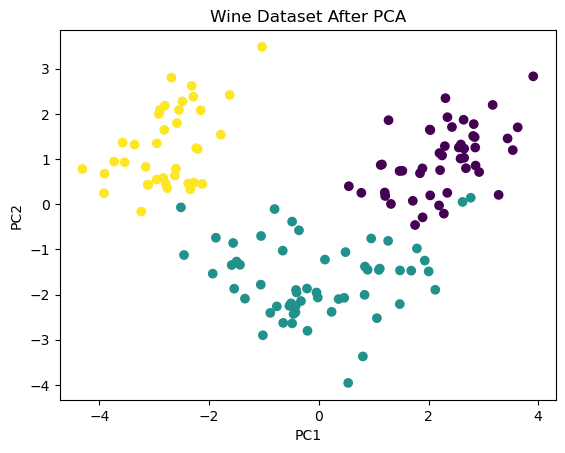

Variance Retained: 0.5506277578733125


In [7]:
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X_train)

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap="viridis")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Wine Dataset After PCA")
plt.show()

print("Variance Retained:", pca2.explained_variance_ratio_.sum())

## 6. Cumulative explained variance

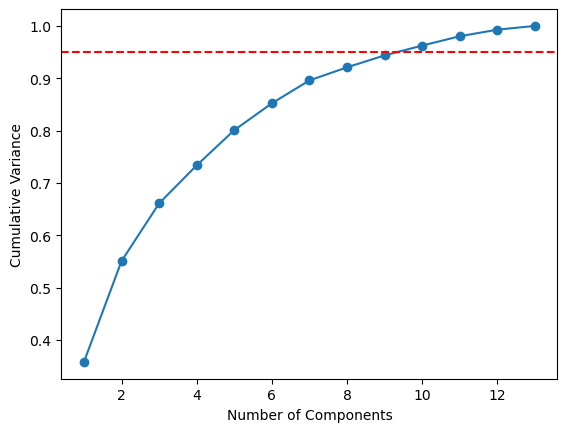

In [8]:
pca = PCA().fit(X_train)

variance = pca.explained_variance_ratio_.cumsum()

plt.plot(range(1, len(variance) + 1), variance, marker="o")
plt.axhline(0.95, color="red", linestyle="--")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.show()

## 7.Classification Report

In [9]:
print("Classification Report Before PCA:")
print(classification_report(y_test, knn.predict(X_test)))

print("Classification Report After PCA:")
print(classification_report(y_test, knn2.predict(X_test_pca)))

Classification Report Before PCA:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36

Classification Report After PCA:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36

